# Environment 4: Bigger Grid + Black Holes (Ultimate Challenge)
### Comparative Evaluation: Training From Scratch (5000 eps) vs. Full Curriculum Transfer (2000 eps)

In **Environment 4**, the complexity scales dramatically:
- **Bigger Grid**: $12 \times 10$ (12 columns, 10 rows) — 2.5× more cells than previous environments.
- **More Mines**: **15 hidden mines** scattered across the interior.
- **Black Holes** : **4 trap tiles** that capture the agent for **3 steps** before releasing it, costing **−2.0 per trapped step** and draining the timer budget.
- **Sidewalks**: **OFF**.
- **Random Hazards**: Randomized every episode (mines and black holes).
- **Goal Zone**: The entire right column (`col 11`, rows 0–9). **+100 reward on WIN**.
- **Action Space**: 4 pure directional movements (`UP, DOWN, LEFT, RIGHT`).

---

### Core Comparative Investigation:
We conduct an empirical two-way comparison:
1. **Condition A (From Scratch)**: Agent trained completely fresh on the $12 \times 10$ board with black holes for **`5000 episodes`**.
2. **Condition B (Full Curriculum Transfer & Fine-Tuned)**: Agent pre-trained through the entire curriculum (Env 1 $\to$ Env 2 $\to$ Env 3), fine-tuned for **`2000 episodes`**.

We measure:
- **Zero-Shot Adaptability**: Does pre-training on $8 \times 6$ grids transfer cross-dimensionally to a $12 \times 10$ board?
- **Sample Efficiency ROI**: Can curriculum transfer reach higher win rates with 60% less training data (2000 vs 5000 episodes)?
- **Computational Speedup**: Training wall-clock time comparison.
- **Schema Representation**: State-Value potential field $V(s)$ on a larger grid with trap sinkholes.
- **Curriculum Stability**: Complete 4-environment retention benchmark.



## 1. Setup & Environment Registration


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch

import environment
from environment.grid_nav_env import (
    GridNavEnv, ACTION_NAMES,
    MOVE_UP, MOVE_DOWN, MOVE_LEFT, MOVE_RIGHT
)
from models.grid_dqn_agent import GridNavDQNAgent, GridStateEncoder, train_dqn_agent
from notebooks.visualizer import (
    record_episode, record_winning_episode, plot_trajectory,
    draw_grid_state, plot_q_value_heatmap, evaluate_agent_retention,
    run_forgetting_benchmark, plot_transfer_comparison
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
print("Environment 4 registered successfully!")



PyTorch version: 2.10.0+cpu
CUDA Available:  False
Environment 4 registered successfully!


## 2. Inspecting Environment 4 Layout ($12 	times 10$ with Black Holes)
We inspect the larger grid dimensions, 15 mines, and 4 black hole traps (shown in purple).



Environment 4 Specifications:
  Grid Dimensions:    12 cols x 10 rows (120 tiles)
  Number of Mines:    15
  Black Holes:        4 (traps agent for 3 steps)
  Sidewalks Active:   False (OFF!)
  Max Steps Budget:   240
  Action Space:       Discrete(4)
  Initial Agent Pos:  [0 0]


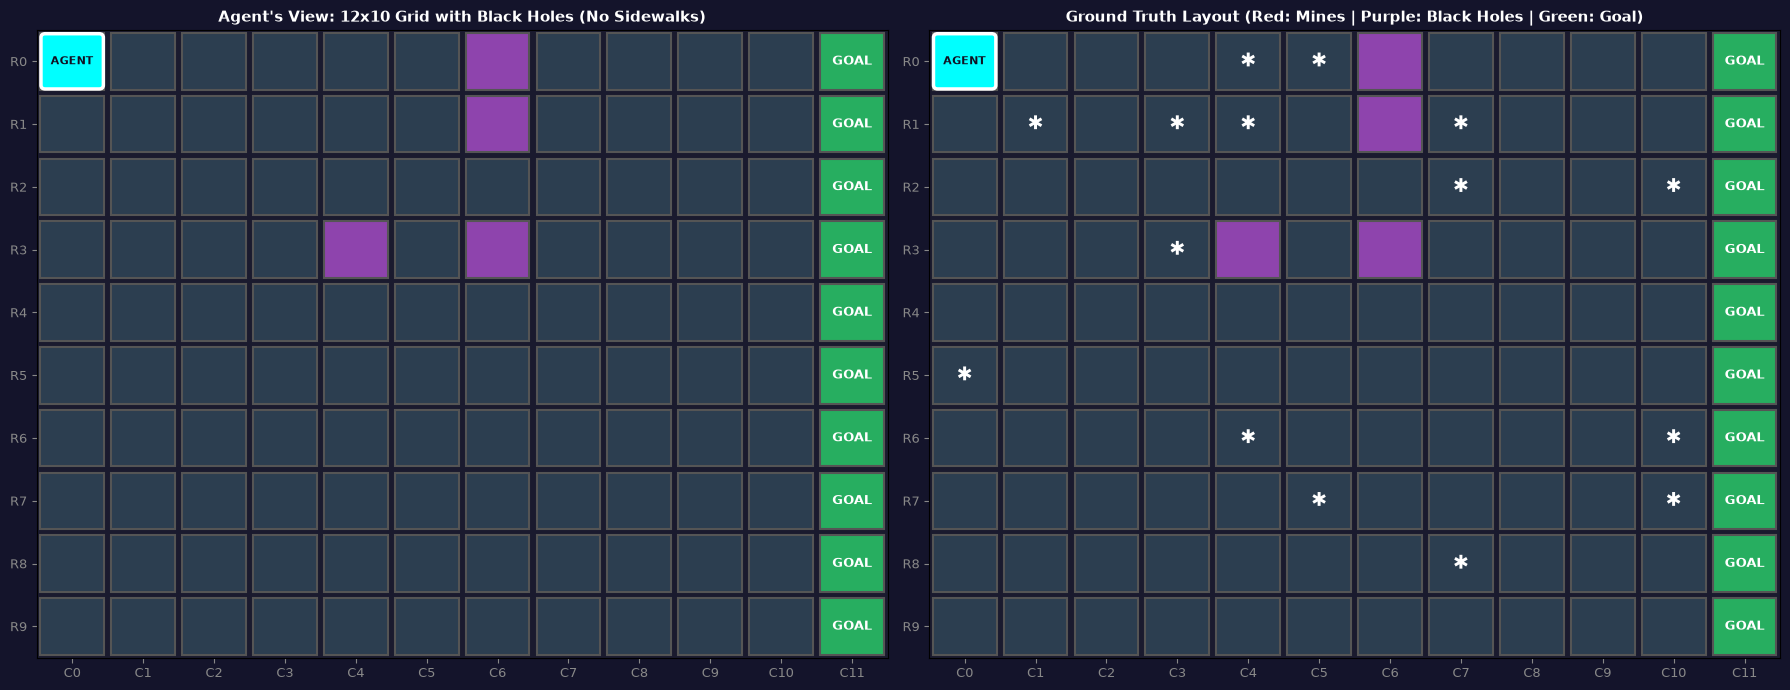

In [2]:
env = gym.make("GridNavMinesweeper-v4")
obs, info = env.reset(seed=42)

print("Environment 4 Specifications:")
print(f"  Grid Dimensions:    {env.unwrapped.grid_width} cols x {env.unwrapped.grid_height} rows (120 tiles)")
print(f"  Number of Mines:    {env.unwrapped.num_mines}")
print(f"  Black Holes:        {env.unwrapped.num_black_holes} (traps agent for {env.unwrapped.black_hole_trap_steps} steps)")
print(f"  Sidewalks Active:   {env.unwrapped.sidewalks_on} (OFF!)")
print(f"  Max Steps Budget:   {env.unwrapped.max_steps}")
print(f"  Action Space:       {env.action_space}")
print(f"  Initial Agent Pos:  {obs['agent_pos']}")

# Plot layout: Agent View vs Ground Truth
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), facecolor="#14142B")

frame_visible = {
    "board": obs["board"],
    "cell_types": obs["cell_types"],
    "agent_pos": obs["agent_pos"],
    "action_name": "AGENT VIEW",
    "reward": 0.0,
    "event": "start",
    "step": 0,
    "mine_map": env.unwrapped._mine_map,
}
draw_grid_state(ax1, frame_visible, show_mines=False)
ax1.set_title("Agent's View: 12x10 Grid with Black Holes (No Sidewalks)", color="white", fontsize=11, fontweight="bold")

draw_grid_state(ax2, frame_visible, show_mines=True)
ax2.set_title("Ground Truth Layout (Red: Mines | Purple: Black Holes | Green: Goal)", color="white", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()



## 3. Zero-Shot Evaluation: Testing the Env 3 Agent on the $12 \times 10$ Grid

Thanks to adaptive spatial pooling and egocentric convolution features, the Q-network weights learned on $8 \times 6$ grids can run directly on the $12 \times 10$ board.



Loaded Env 3 checkpoint from checkpoints/env3_dqn.pt

=== Zero-Shot Performance on Env 4 (12x10) ===
  Steps Taken:  4
  Won:          False
  Final Event:  mine_hit
  Total Reward: -99.0


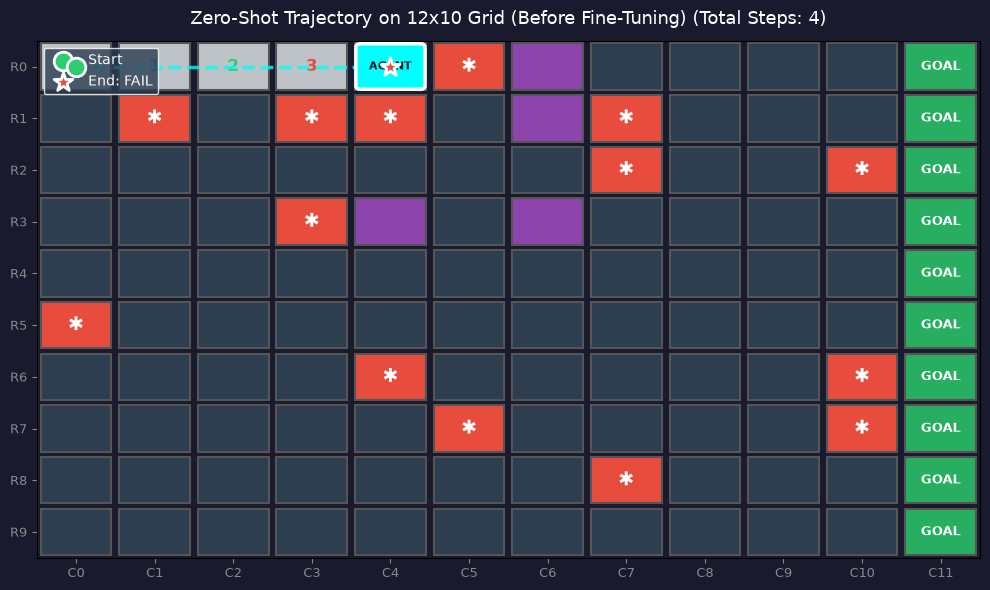

In [3]:
zero_shot_agent = GridNavDQNAgent(
    grid_size=(env.unwrapped.grid_width, env.unwrapped.grid_height),
    num_actions=4,
)

checkpoint_path = "checkpoints/env3_dqn.pt"
if os.path.exists(checkpoint_path):
    zero_shot_agent.load(checkpoint_path, load_buffer=False)
    print(f"Loaded Env 3 checkpoint from {checkpoint_path}")
else:
    print(f"Checkpoint not found at {checkpoint_path} — please run Notebook 3 first!")

eval_env = gym.make("GridNavMinesweeper-v4", seed=42)
zero_shot_history = record_episode(eval_env, zero_shot_agent, evaluate=True, seed=42)

print(f"\n=== Zero-Shot Performance on Env 4 (12x10) ===")
print(f"  Steps Taken:  {len(zero_shot_history)-1}")
print(f"  Won:          {zero_shot_history[-1].get('won')}")
print(f"  Final Event:  {zero_shot_history[-1].get('event')}")
print(f"  Total Reward: {sum(f['reward'] for f in zero_shot_history):.1f}")

plot_trajectory(zero_shot_history, title="Zero-Shot Trajectory on 12x10 Grid (Before Fine-Tuning)")



## 4. Condition A: Training From Scratch on Env 4 (5000 Episodes)

We train a fresh agent with random weight initialization on the $12 \times 10$ board with black holes for **`5000 episodes`**.



In [4]:
NUM_EPISODES_SCRATCH = 5000

scratch_env = gym.make("GridNavMinesweeper-v4")

scratch_agent = GridNavDQNAgent(
    grid_size=(scratch_env.unwrapped.grid_width, scratch_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.990, 
    batch_size=64,
    target_update_freq=10,
)

scratch_metrics = train_dqn_agent(
    env=scratch_env,
    agent=scratch_agent,
    num_episodes=NUM_EPISODES_SCRATCH,
    update_freq=8,
    warmup_steps=64,
    verbose_freq=250,
)

os.makedirs("checkpoints", exist_ok=True)
scratch_agent.save("checkpoints/env4_scratch.pt", save_buffer=True)
print(f"\nSaved Scratch model to checkpoints/env4_scratch.pt")



Starting DQN Training on GridNavEnv for 5000 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  250 |    -51.8 |      24.0% |     10 |    0.081 |     0.0% |     22.1s


  500 |    -92.9 |      12.0% |      4 |    0.050 |     0.0% |     52.0s


  750 |    -59.2 |      20.0% |     10 |    0.050 |     0.0% |     68.2s


 1000 |    -61.5 |      20.0% |      3 |    0.050 |     0.0% |     85.2s


 1250 |    -86.5 |       8.0% |      1 |    0.050 |     0.0% |    102.3s


... (12 outputs left out)

 4500 |    -69.4 |      24.0% |     12 |    0.050 |     8.3% |    379.9s


 4750 |    -73.4 |      20.0% |      3 |    0.050 |     0.0% |    418.8s


 5000 |   -101.7 |      12.0% |     17 |    0.050 |     0.0% |    489.7s
═══════════════════════════════════════════════════════════════════════════
Training completed in 489.66s!
First Goal reached at Episode 33!
Final 25-episode win rate: 12.0%



Saved Scratch model to checkpoints/env4_scratch.pt


## 5. Condition B: Full Curriculum Transfer (Env 1+2+3) & Fine-Tune (2000 Episodes)

We load the weights pre-trained across Envs 1–3, clear the replay buffer, and fine-tune for **`2000 episodes`** (a 60% reduction in training budget).



In [5]:
NUM_EPISODES_TRANSFER = 2000

transfer_env = gym.make("GridNavMinesweeper-v4")

transferred_agent = GridNavDQNAgent(
    grid_size=(transfer_env.unwrapped.grid_width, transfer_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.990,
    batch_size=64,
    target_update_freq=10,
)

if os.path.exists("checkpoints/env3_dqn.pt"):
    transferred_agent.load("checkpoints/env3_dqn.pt", load_buffer=False)
    transferred_agent.clear_buffer()
    transferred_agent.epsilon = 1.0
    print("Successfully loaded full curriculum pre-trained weights (Env 1+2+3)!")
else:
    print("Env 3 checkpoint not found — starting fresh.")

transfer_metrics = train_dqn_agent(
    env=transfer_env,
    agent=transferred_agent,
    num_episodes=NUM_EPISODES_TRANSFER,
    update_freq=8,
    warmup_steps=64,
    verbose_freq=250,
)

transferred_agent.save("checkpoints/env4_transferred.pt", save_buffer=True)
transferred_agent.save("checkpoints/env4_dqn.pt", save_buffer=True)
print(f"\nSaved Transferred model to checkpoints/env4_transferred.pt and checkpoints/env4_dqn.pt")



Successfully loaded full curriculum pre-trained weights (Env 1+2+3)!
Starting DQN Training on GridNavEnv for 2000 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  250 |    -87.4 |      12.0% |      1 |    0.081 |     0.0% |     44.3s


  500 |    -28.0 |      36.0% |     11 |    0.050 |     0.0% |     59.9s


  750 |    -83.9 |       8.0% |      2 |    0.050 |   100.0% |     73.6s


 1000 |    -68.8 |      16.0% |      5 |    0.050 |     0.0% |     91.4s


 1250 |    -68.0 |      16.0% |      1 |    0.050 |     0.0% |    108.6s


 1500 |    -37.7 |      32.0% |      7 |    0.050 |    28.6% |    127.6s


 1750 |    -59.1 |      20.0% |      2 |    0.050 |     0.0% |    145.8s


 2000 |    -77.8 |      12.0% |     15 |    0.050 |     6.7% |    161.1s
═══════════════════════════════════════════════════════════════════════════
Training completed in 161.14s!
First Goal reached at Episode 36!
Final 25-episode win rate: 12.0%



Saved Transferred model to checkpoints/env4_transferred.pt and checkpoints/env4_dqn.pt


## 6. Comparative Results: From Scratch (5000 eps) vs. Transferred (2000 eps)
We compare success rates, learning speed, steps taken, and training duration on the large grid.



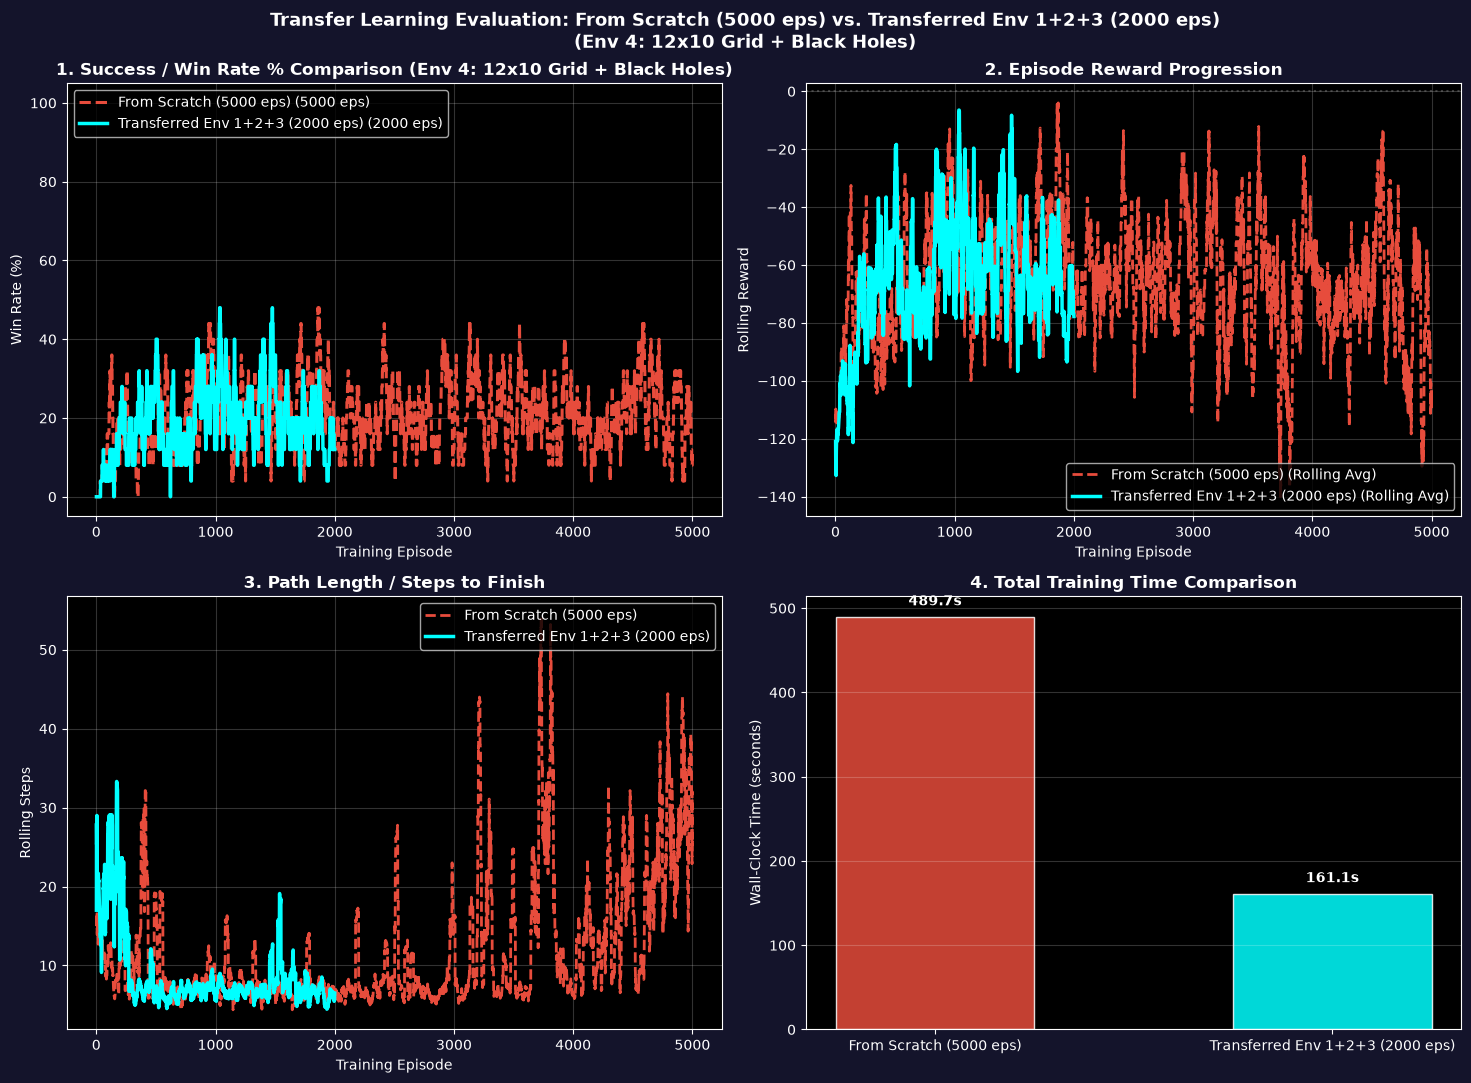


=== Summary Comparison Table ===
Condition                           |  Episodes | Final Win Rate | Total Time
---------------------------------------------------------------------------
Condition A: From Scratch           |      5000 |          12.0% |     489.7s
Condition B: Full Curriculum Transfer |      2000 |          12.0% |     161.1s


In [6]:
plot_transfer_comparison(
    scratch_metrics=scratch_metrics,
    transfer_metrics=transfer_metrics,
    env_name="Env 4: 12x10 Grid + Black Holes",
    scratch_label=f"From Scratch ({NUM_EPISODES_SCRATCH} eps)",
    transfer_label=f"Transferred Env 1+2+3 ({NUM_EPISODES_TRANSFER} eps)",
)

print("\n=== Summary Comparison Table ===")
print(f"{'Condition':35s} | {'Episodes':>9} | {'Final Win Rate':>14} | {'Total Time':>10}")
print("-" * 75)
print(f"{'Condition A: From Scratch':35s} | {NUM_EPISODES_SCRATCH:>9d} | {scratch_metrics['rolling_win_rate'][-1]:>13.1f}% | {scratch_metrics['cumulative_time'][-1]:>9.1f}s")
print(f"{'Condition B: Full Curriculum Transfer':35s} | {NUM_EPISODES_TRANSFER:>9d} | {transfer_metrics['rolling_win_rate'][-1]:>13.1f}% | {transfer_metrics['cumulative_time'][-1]:>9.1f}s")



## 7. Trajectory Analysis: Navigating the $12 \times 10$ Minefield
We inspect winning and hazard avoidance trajectories on the large grid.



Replaying best winning trajectory (Ep 36) | Steps: 11 | Won: True


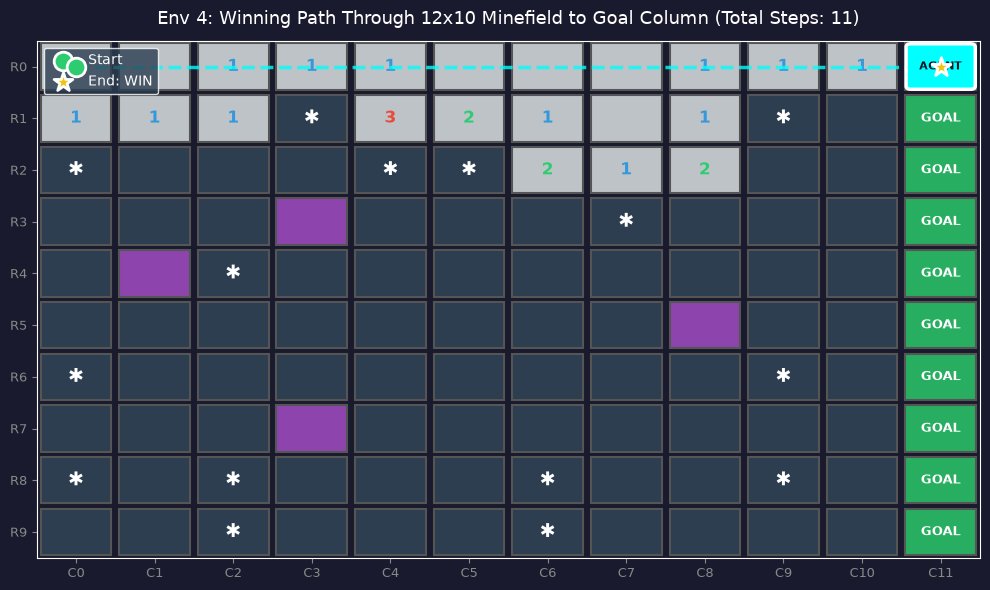

In [7]:
eval_env_test = gym.make("GridNavMinesweeper-v4", seed=42)

if transfer_metrics.get("best_winning_history") is not None:
    history_win = transfer_metrics["best_winning_history"]
    print(f"Replaying best winning trajectory (Ep {transfer_metrics['first_win_episode']}) | Steps: {len(history_win)-1} | Won: {history_win[-1].get('won')}")
else:
    history_win = record_winning_episode(eval_env_test, transferred_agent)

plot_trajectory(history_win, title="Env 4: Winning Path Through 12x10 Minefield to Goal Column")



## 8. Schema Representation on $12 \times 10$ Grid: State-Value Heatmap $V(s)$
We inspect the State-Value field $V(s) = \max_a Q(s, a)$ on the $12 \times 10$ board with black holes.
Notice the spatial gradient climbing toward Column 11!



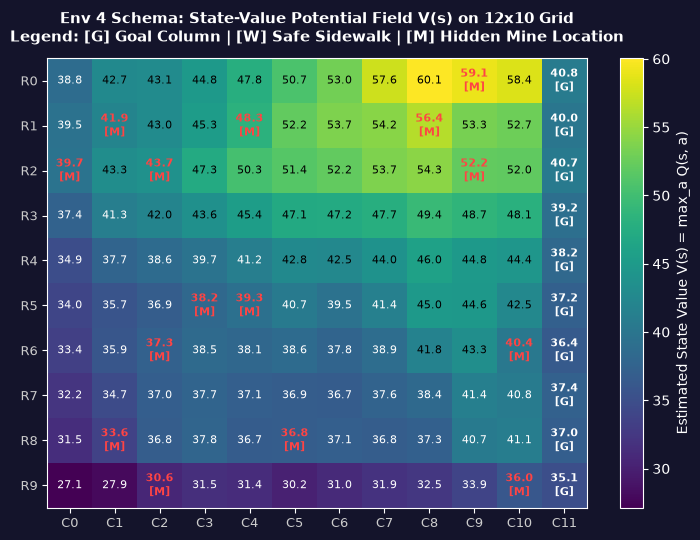

In [8]:
plot_q_value_heatmap(
    agent=transferred_agent,
    env=eval_env_test,
    title="Env 4 Schema: State-Value Potential Field V(s) on 12x10 Grid"
)



## 9. Grand Curriculum Benchmark: Testing the Agent Across All 4 Environments

We test the final agent on all 4 curriculum stages:
1. **Env 1**: Sidewalks ON ($8 \times 6$)
2. **Env 2**: Sidewalks OFF, fixed mines ($8 \times 6$)
3. **Env 3**: Sidewalks OFF, randomized mines ($8 \times 6$)
4. **Env 4**: $12 \times 10$ Grid, 15 mines, 4 Black Holes



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v1 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(
C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v2 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(
C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


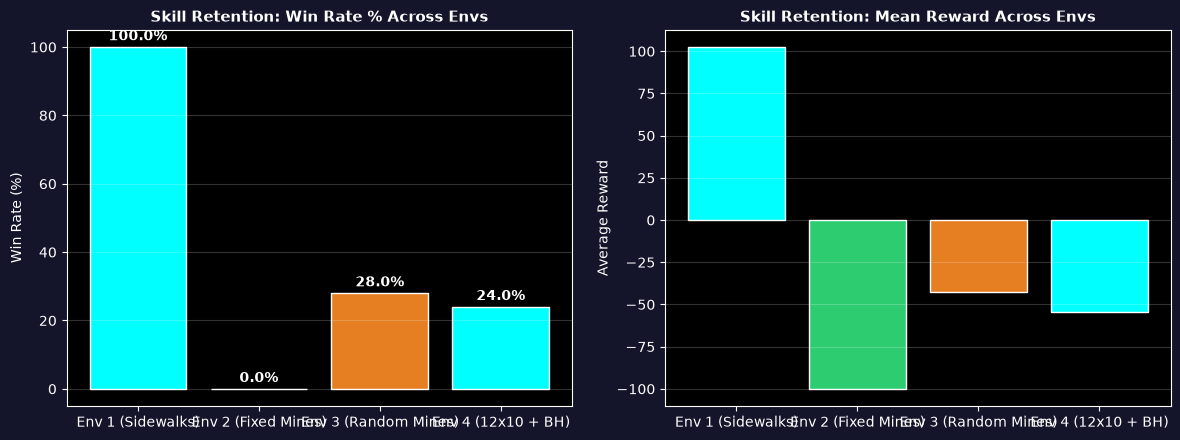


=== Grand Curriculum Retention Benchmark ===
Env 1 (Sidewalks)         | Win Rate: 100.0% | Mean Reward: +102.5
Env 2 (Fixed Mines)       | Win Rate:   0.0% | Mean Reward: -100.0
Env 3 (Random Mines)      | Win Rate:  28.0% | Mean Reward:  -42.8
Env 4 (12x10 + BH)        | Win Rate:  24.0% | Mean Reward:  -54.4


In [9]:
env1_eval = gym.make("GridNavMinesweeper-v1", seed=42)
env2_eval = gym.make("GridNavMinesweeper-v2", seed=42)
env3_eval = gym.make("GridNavMinesweeper-v3")
env4_eval = gym.make("GridNavMinesweeper-v4")

full_retention = evaluate_agent_retention(
    agent=transferred_agent,
    env_dict={
        "Env 1 (Sidewalks)":   env1_eval,
        "Env 2 (Fixed Mines)": env2_eval,
        "Env 3 (Random Mines)":env3_eval,
        "Env 4 (12x10 + BH)":  env4_eval,
    },
    episodes_per_env=25
)

print("\n=== Grand Curriculum Retention Benchmark ===")
for name, res in full_retention.items():
    print(f"{name:25s} | Win Rate: {res['win_rate']:5.1f}% | Mean Reward: {res['avg_reward']:+6.1f}")

